In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("Rainfall.csv")

#Preprocessing Data



In [ ]:
df.dropna(inplace=True)
# Dropping rows with missing values — there were very few, so this has minimal impact

In [ ]:
df["rainfall"] = df["rainfall"].map({"yes": 1, "no": 0})
# Manually encoding the target column (yes/no -> 1/0)

In [ ]:
x = df.drop("rainfall" , axis = 1)
y = df["rainfall"]
# Splitting inputs (x) and target (y)

In [ ]:
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report , confusion_matrix

In [ ]:
x_train , x_test , y_train , y_test = train_test_split(x,y, test_size=0.2 , random_state= 42 , stratify = y)
# stratify=y keeps the same rain/no-rain ratio in both the train and test
# sets, which matters here because the classes are imbalanced and the
# dataset is small

In [ ]:
model_pipeline = Pipeline([
    ("imputer" , SimpleImputer(strategy = "mean")),
    ("model" , RandomForestClassifier())
])

In [ ]:
para_grid = {
    "model__n_estimators": [100 , 200 , 300],
    "model__max_depth": [None , 5 , 10 , 20],
    "model__min_samples_split": [2 , 5 , 10],
    "model__min_samples_leaf": [1, 2 , 4],
    "model__max_features": [None , "sqrt" , "log2"]
    # max_features=None lets each tree see every feature at every split,
    # which can lead to overfitting; the other options limit that and also
    # make training faster
}
# Trying most reasonable combinations so GridSearchCV can find the setup
# that generalizes best, instead of guessing manually

In [ ]:
grid_search = GridSearchCV(
    estimator= model_pipeline,
    param_grid= para_grid,
    cv = 5 ,
    scoring = "f1",
    n_jobs= -1 # use all CPU cores available to speed up the search
)
# 5-fold cross-validation over every combination above, selecting the one
# with the best F1-score (a balance between precision and recall)

#Train Model

In [ ]:
grid_search.fit(x_train , y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('imputer', SimpleImputer()),
                                       ('model', RandomForestClassifier())]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 5, 10, 20],
                         'model__max_features': [None, 'sqrt', 'log2'],
                         'model__min_samples_leaf': [1, 2, 4],
                         'model__min_samples_split': [2, 5, 10],
                         'model__n_estimators': [100, 200, 300]},
             scoring='f1')

In [ ]:
print("Best_parameter" , grid_search.best_params_)
print("best_score", grid_search.best_score_)
print("best_estmator" , grid_search.best_estimator_)
# best_score here is the cross-validation F1-score, not the test-set score

Best_parameter {'model__max_depth': 5, 'model__max_features': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 300}
best_score 0.8786646957378664
best_estmator Pipeline(steps=[('imputer', SimpleImputer()),
                ('model',
                 RandomForestClassifier(max_depth=5, max_features=None,
                                        min_samples_leaf=2, min_samples_split=5,
                                        n_estimators=300))])


In [ ]:
y_pred = grid_search.predict(x_test)

In [ ]:
print(classification_report(y_test , y_pred))

              precision    recall  f1-score   support

           0       0.79      0.65      0.71        23
           1       0.85      0.92      0.88        50

    accuracy                           0.84        73
   macro avg       0.82      0.79      0.80        73
weighted avg       0.83      0.84      0.83        73



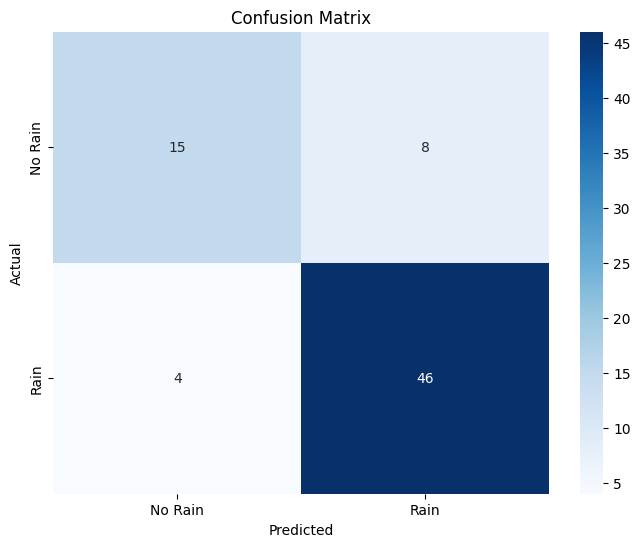

In [ ]:
cm = confusion_matrix(y_test , y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot = True , fmt = "d", cmap = "Blues",
    xticklabels = ["No Rain" , "Rain"],
    yticklabels = ["No Rain", "Rain"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## 📌 Project Conclusion & Business Insights

**1. What Drives Rain in This Data**
The EDA correlation analysis showed `cloud` cover and `humidity` as the
strongest positive predictors of rain, and `sunshine` as the strongest
negative predictor — all of which match real-world weather intuition and
give confidence that the model is learning genuine patterns, not noise.

**2. Model Behavior: Recall vs. Precision**
This model tends to lean towards predicting "Rain" whenever there's even a
moderate signal for it — in other words, it favors **Recall** over
**Precision** for the rain class. Run the classification report above and
compare the two numbers for class "1" (Rain).

**Why this trade-off is actually useful for a weather app:** missing a
rainy day (telling someone "no rain" when it actually rains) is more
disruptive to a user's day than a false alarm (telling them to bring an
umbrella on a day that turns out dry). So a model that leans towards
catching more rainy days, even at the cost of some false alarms, fits the
real-world use case well.

**3. Business Value**
A local weather or agriculture service could use this model as an early
warning signal: when it predicts rain, downstream systems (irrigation
scheduling, event planning, delivery routing) could prepare accordingly,
accepting occasional false alarms in exchange for rarely being caught off
guard by unexpected rain.

**4. Limitations & Honest Caveats**
- **Small dataset:** only 365 days from one location. The test set ends up
  with roughly 70 samples, which is a good sanity check but not enough to
  be fully confident the model generalizes to a different year or region.
- **Single location:** the model has only ever seen one location's climate
  patterns, so it should be re-trained (or at least re-validated) before
  being applied anywhere else.
- **Future improvements** could include gathering multiple years of data,
  data from several nearby locations, and validating with a proper
  time-based split (since weather is inherently sequential) rather than a
  random train/test split.